# Comparing alpha diversity metrics in the three antibiotic use groups

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator
from regression_functions import *

# apply settings so the lib knows where the data is
import arivale_data_interface as adi
adi.apply_isb_config()

## Read in covariates

In [4]:
abx_alphas = pd.read_csv("../data/rh_abx_covar_alpha_divs_rarefied.csv", dtype={"public_client_id":str})

In [5]:
abx_alphas = abx_alphas.dropna(subset='observed_features')

In [6]:
abx_alphas.public_client_id.nunique()

1970

In [7]:
abx_alphas.days_in_program = abx_alphas.days_in_program.astype(float)

## Start with alpha diversity

In [8]:
args = ['observed_features', 'berger_parker', 'shannon_index']

In [9]:
# Define formula for results and look at the difference between including GFR vs not 
formula = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
           "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) +"
           "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + C(vendor_dashboard)")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"

In [10]:
tests_three_diversities = run_tests(args, abx_alphas, formula, abx_term_three)
tests_three_diversities # Three versus none

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
observed_features,observed_features,-9.967761,1.227539,-8.120114,-12.375184,-7.560337,8.155584e-16,1970.0,1.223338e-15
berger_parker,berger_parker,0.048859,0.006995,6.984867,0.035141,0.062578,3.893825e-12,1970.0,3.893825e-12
shannon_index,shannon_index,-0.237203,0.026085,-9.093423,-0.288361,-0.186046,2.293182e-19,1970.0,6.879545e-19


In [11]:
three_diversity_qs = tests_three_diversities.q.tolist()

In [12]:
tests_twelve_diversities = run_tests(args, abx_alphas, formula, abx_term_twelve)
tests_twelve_diversities #Twelve versus none

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
observed_features,observed_features,-5.409740,1.093417,-4.947555,-7.554126,-3.265355,8.158298e-07,1970.0,0.000002
berger_parker,berger_parker,0.017231,0.006231,2.765493,0.005011,0.029451,5.737093e-03,1970.0,0.005737
shannon_index,shannon_index,-0.100924,0.023235,-4.343614,-0.146492,-0.055356,1.473351e-05,1970.0,0.000022


In [13]:
twelve_diversity_qs = tests_twelve_diversities.q.tolist()

### Plot results

In [14]:
sns.set_style(style="whitegrid",  rc={"xtick.bottom": True, 'ytick.left': True})
div_metric = ['observed_features','berger_parker', 'shannon_index']
order = ['none', 'twelve', 'three']
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}
x_labels = ['None', '3-12 mo.', '0-3 mo.']
y_labels= ['Observed Features','Berger Parker', 'Shannon Index']

<Figure size 640x480 with 0 Axes>

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 2.45e-06
none vs. three: q = 1.22e-15
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 5.74e-03
none vs. three: q = 3.89e-12
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 2.21e-05
none vs. three: q = 6.88e-19


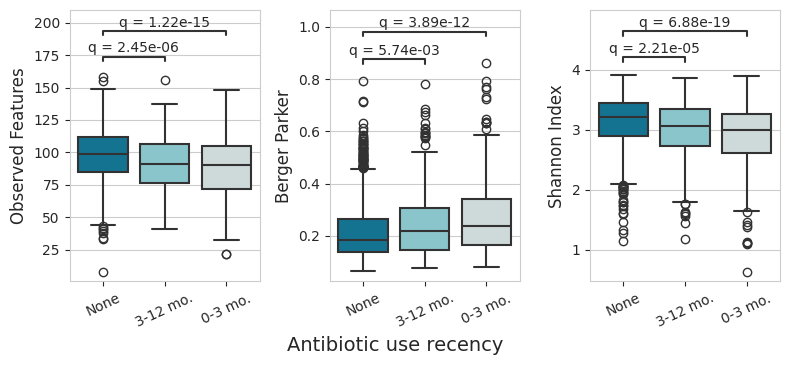

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(8, 4))
axes = axes.flatten()

comparisons = [('none', 'three'), ('none', 'twelve')]

for i, feature in enumerate(div_metric):
    sns.boxplot(data=abx_alphas, x='abx_recency', y=feature,
                linewidth=1.5, hue='abx_recency', palette=my_pal, 
                order=order, ax=axes[i], legend=False, showfliers=True)
    
    # Format the axes
    current_xticks = axes[i].get_xticks()
    axes[i].set_xticks(current_xticks, labels=x_labels, rotation=25)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(y_labels[i], size=12)

    # Define q-value list
    qvalues = [three_diversity_qs[i], twelve_diversity_qs[i]]
    formatted_qvalues = [f"q = {q:.2e}" for q in qvalues]

    # Annotate
    annotator = Annotator(axes[i], comparisons, data=abx_alphas, x='abx_recency', y=feature, order=order)
    annotator.set_custom_annotations(formatted_qvalues)
    annotator.annotate()
    
fig.supxlabel('Antibiotic use recency', y=0.06, size=14)

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to make room for the main title
plt.savefig("figures/abx_use_alphas.pdf", bbox_inches="tight")
plt.show()

## How does recent antibiotic use change SCFA production? 
For this we will use data from Nick's MCMM

In [16]:
arivale_predictions = pd.read_csv('../data/updated_arivale_scfas.csv')
shannon_merged_scfa = abx_alphas.merge(arivale_predictions, how='left', on='public_client_id')
len(shannon_merged_scfa)

1970

### Run linear regressions

In [17]:
args_scfa = ['butyrate', 'propionate']

In [18]:
tests_threemo_scfa = run_tests(args_scfa, shannon_merged_scfa, formula, abx_term_three)
tests_threemo_scfa

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
butyrate,butyrate,-1.480104,0.447622,-3.306597,-2.357970,-0.602238,0.000961,1970.0,0.000961
propionate,propionate,-0.794436,0.174439,-4.554228,-1.136543,-0.452330,0.000006,1970.0,0.000011


In [19]:
three_scfa_qs = tests_threemo_scfa.q.tolist()

In [20]:
tests_twelvemo_scfa = run_tests(args_scfa, shannon_merged_scfa, formula, abx_term_twelve)
tests_twelvemo_scfa

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
butyrate,butyrate,-0.627311,0.398714,-1.573336,-1.409260,0.154638,0.115803,1970.0,0.126886
propionate,propionate,-0.237288,0.155380,-1.527149,-0.542016,0.067439,0.126886,1970.0,0.126886


In [21]:
twelve_scfa_qs = tests_twelvemo_scfa.q.tolist()

In [22]:
shannon_merged_scfa.to_csv('../data/rh_abx_covar_alphadivs_scfa.csv', index=False)

In [23]:
scfa = ['butyrate','propionate']
order = ['none', 'twelve', 'three']
x_labels = ['None', '3-12 mo.', '0-3 mo.']
comparisons = [('none', 'three'), ('none', 'twelve')]

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 1.27e-01
none vs. three: q = 9.61e-04
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: q = 1.27e-01
none vs. three: q = 1.12e-05


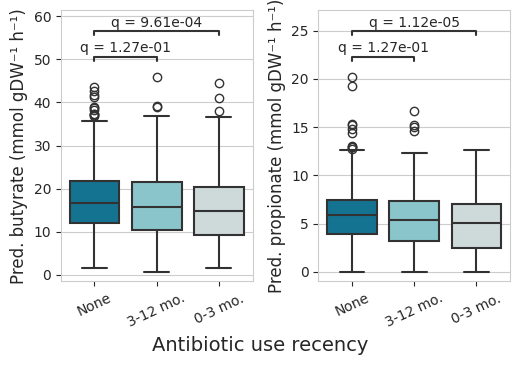

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(5.3, 4))
axes = axes.flatten()

# Plot each boxplot in its respective subplot
for i, feature in enumerate(scfa):
    sns.boxplot(data=shannon_merged_scfa, x='abx_recency', y=feature,
                linewidth=1.5, hue='abx_recency', palette=my_pal, 
                order=order, ax=axes[i], legend=False, showfliers=True)

    # Adjust axes
    current_xticks = axes[i].get_xticks()
    axes[i].set_xticks(current_xticks, labels=x_labels, rotation=25)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(f'Pred. {feature} (mmol gDW\u207B\u00B9 h\u207B\u00B9)', size=12)
    
    # Define q-value list
    qvalues = [three_scfa_qs[i], twelve_scfa_qs[i]]
    formatted_qvalues = [f"q = {q:.2e}" for q in qvalues]

    # Annotate
    annotator = Annotator(axes[i], comparisons, data=shannon_merged_scfa, x='abx_recency', y=feature, order=order)
    annotator.set_custom_annotations(formatted_qvalues)
    annotator.annotate()
    
fig.supxlabel('Antibiotic use recency', y=0.06, size=14)

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to make room for the main title
plt.savefig("figures/abx_recency_mcmm_scfas.pdf", bbox_inches="tight")
plt.show()

### CAZYmes

In [ ]:
# create feature table

In [39]:
cazy_meta = pd.read_csv('../data/CAZY_meta.csv', dtype = {'public_client_id': str})

In [40]:
cazy_families = cazy_meta[['public_client_id', 'n_families']]

In [41]:
shannon_merged_scfa_cazy = shannon_merged_scfa.merge(cazy_families, how='left', on='public_client_id')

In [42]:
tests_three_scfa = run_tests(['n_families'], shannon_merged_scfa_cazy, formula, abx_term_three)
tests_three_scfa

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
n_families,n_families,-2.59331,0.294919,-8.793299,-3.171716,-2.014903,3.236683e-18,1877.0,3.236683e-18


In [43]:
tests_twelve_scfa = run_tests(['n_families'], shannon_merged_scfa_cazy, formula, abx_term_twelve)
tests_twelve_scfa

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
n_families,n_families,-1.205002,0.239013,-5.041571,-1.673763,-0.73624,5.065412e-07,1877.0,5.065412e-07


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

none vs. twelve: p = 5.07e-07
none vs. three: p = 3.24e-18


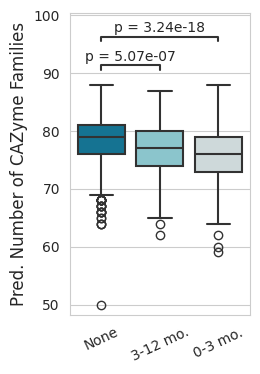

In [44]:
# List of columns to plot
order = ['none', 'twelve', 'three']
x_labels = ['None', '3-12 mo.', '0-3 mo.']
sns.set_style(style="whitegrid")

fig, ax = plt.subplots(1, 1, figsize=(2.7, 4))
sns.boxplot(data=shannon_merged_scfa_cazy, x='abx_recency', y='n_families',
                linewidth=1.5, hue='abx_recency', palette=my_pal, 
                order=order, legend=False, showfliers=True)

current_xticks = ax.get_xticks()
ax.set_xticks(current_xticks, labels=x_labels, rotation=25)
ax.set_xlabel('')
ax.set_ylabel('Pred. Number of CAZyme Families', size=12)

# Define q-value list
pvalues = [tests_three_scfa.p.iloc[0], tests_twelve_scfa.p.iloc[0]]
formatted_pvalues = [f"p = {p:.2e}" for p in pvalues]

# Annotate
annotator = Annotator(ax, comparisons, data=shannon_merged_scfa_cazy, x='abx_recency', y='n_families', order=order)
annotator.set_custom_annotations(formatted_pvalues)
annotator.annotate()

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to make room for the main title
#plt.savefig("figures/abx_num_CAZyme_boxplot_stats_reg_vendor.pdf", bbox_inches="tight")
plt.show()